<a href="https://colab.research.google.com/github/NadiiaStuzhuk/DI-Bootcamp-Stage1/blob/main/Daily_Challenge_Comprehensive_Mobile_Price_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# 1. Data Loading and Exploration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Load the dataset
df = pd.read_csv('train.csv')

# 2. Inspect shape, columns, and data types
print("=== Dataset Dimension & Data Types ===")
print(f"Total Records: {df.shape[0]}, Total Attributes: {df.shape[1]}")
print(df.info())

# 3. Inspect target variable distribution
print("\n=== Target Variable ('price_range') Distribution ===")
print(df['price_range'].value_counts())
# 0: Low Cost, 1: Medium Cost, 2: High Cost, 3: Very High Cost (Perfect 500 balance across all 4 classes)

# 4. First 5 rows overview
display(df.head())

# 5. Basic Descriptive Statistics
print("\n=== Summary Statistics (Pandas) ===")
display(df.describe().T.round(2))

=== Dataset Dimension & Data Types ===
Total Records: 2000, Total Attributes: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1



=== Summary Statistics (Pandas) ===


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.52,439.42,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.50,0.50,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52,0.82,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.51,0.50,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.31,4.34,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52,0.50,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.05,18.15,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50,0.29,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.25,35.40,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52,2.29,1.0,3.00,4.0,7.00,8.0


In [3]:
# 2. Data Cleaning and Preprocessing

# 1. Check for Missing / Null Values
null_counts = df.isnull().sum()
print("=== Null Values per Column ===")
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else "No missing values found across all 21 columns.")

# 2. Check for Duplicate Records
duplicate_rows = df.duplicated().sum()
print(f"Total duplicate records: {duplicate_rows}")

# 3. Categorical vs Numerical Column Differentiation
# Binary/Categorical features: ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi', 'n_cores']
# Continuous/Numerical features: ['battery_power', 'clock_speed', 'fc', 'int_memory', 'm_dep', 'mobile_wt', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time']
cat_cols = ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi', 'n_cores']
num_cols = [col for col in df.columns if col not in cat_cols + ['price_range']]

print(f"Categorical attributes ({len(cat_cols)}): {cat_cols}")
print(f"Continuous numerical attributes ({len(num_cols)}): {num_cols}")

=== Null Values per Column ===
No missing values found across all 21 columns.
Total duplicate records: 0
Categorical attributes (7): ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi', 'n_cores']
Continuous numerical attributes (13): ['battery_power', 'clock_speed', 'fc', 'int_memory', 'm_dep', 'mobile_wt', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time']


In [9]:
# 3. Statistical Analysis with NumPy and SciPy

# 1. Detailed Statistical Measures (Central Tendency, Variability, Distribution Shape)
stat_summary = []

for col in num_cols:
    data = df[col].values

    # Central Tendency
    mean_val = np.mean(data)
    median_val = np.median(data)
    mode_val = stats.mode(data, keepdims=True)[0][0]

    # Variability
    val_range = np.ptp(data)
    var_val = np.var(data, ddof=1)
    std_val = np.std(data, ddof=1)

    # Distribution Shapes
    skew_val = stats.skew(data)
    kurt_val = stats.kurtosis(data)  # Fisher excess kurtosis

    # Hypothesis Testing & Correlation with Price Range
    pearson_r, pearson_p = stats.pearsonr(data, df['price_range'])
    spearman_r, spearman_p = stats.spearmanr(data, df['price_range'])

    # ANOVA One-Way F-test across the 4 price tiers
    groups = [df[df['price_range'] == k][col].values for k in range(4)]
    f_stat, f_p = stats.f_oneway(*groups)

    stat_summary.append({
        'Feature': col,
        'Mean': round(mean_val, 2),
        'Median': round(median_val, 2),
        'Mode': round(mode_val, 2),
        'Range': round(val_range, 2),
        'Std Dev': round(std_val, 2),
        'Variance': round(var_val, 2),
        'Skewness': round(skew_val, 3),
        'Kurtosis': round(kurt_val, 3),
        'Pearson_r': round(pearson_r, 4),
        'Pearson_p': f"{pearson_p:.2e}",
        'ANOVA_F': round(f_stat, 2),
        'ANOVA_p': f"{f_p:.2e}"
    })

stat_df = pd.DataFrame(stat_summary).sort_values(by='ANOVA_F', ascending=False)
display(stat_df)

# 2. Chi-Square Test of Independence for Categorical Attributes vs Price Range
print("\n=== Chi-Square Independence Tests (Categorical Features vs. Price Range) ===")
for cat in cat_cols:
    contingency_tab = pd.crosstab(df[cat], df['price_range'])
    chi2, chi_p, dof, _ = stats.chi2_contingency(contingency_tab)
    print(f"  • {cat:<15}: Chi2 = {chi2:.4f}, p-value = {chi_p:.4f} -> {'Significant' if chi_p < 0.05 else 'Independent / Not Significant'}")

,Feature,Mean,Median,Mode,Range,Std Dev,Variance,Skewness,Kurtosis,Pearson_r,Pearson_p,ANOVA_F,ANOVA_p
9,ram,2124.21,2146.5,1229.0,3742.0,1084.73,1176643.61,0.007,-1.192,0.9170,0.00e+00,3520.11,0.00e+00
0,battery_power,1238.52,1226.0,618.0,1497.0,439.42,193088.36,0.032,-1.224,0.2007,1.26e-19,31.60,5.95e-20
8,px_width,1251.52,1247.0,874.0,1498.0,432.20,186796.36,0.015,-1.186,0.1658,8.48e-14,22.62,2.12e-14
7,px_height,645.11,564.0,347.0,1960.0,443.78,196941.41,0.666,-0.318,0.1489,2.23e-11,19.48,1.89e-12
5,mobile_wt,140.25,141.0,182.0,120.0,35.40,1253.14,0.007,-1.210,-0.0303,1.76e-01,3.59,1.31e-02
3,int_memory,32.05,32.0,27.0,62.0,18.15,329.27,0.058,-1.216,0.0444,4.69e-02,2.92,3.28e-02
10,sc_h,12.31,12.0,17.0,14.0,4.21,17.75,-0.099,-1.191,0.0230,3.04e-01,2.23,8.32e-02
11,sc_w,5.77,5.0,1.0,18.0,4.36,18.98,0.633,-0.392,0.0387,8.35e-02,1.67,1.71e-01
12,talk_time,11.01,11.0,7.0,18.0,5.46,29.85,0.010,-1.219,0.0219,3.29e-01,1.63,1.81e-01
4,m_dep,0.50,0.5,0.1,0.9,0.29,0.08,0.089,-1.274,0.0009,9.70e-01,1.50,2.12e-01



=== Chi-Square Independence Tests (Categorical Features vs. Price Range) ===
  • blue           : Chi2 = 1.4321, p-value = 0.6980 -> Independent / Not Significant
  • dual_sim       : Chi2 = 1.2865, p-value = 0.7323 -> Independent / Not Significant
  • four_g         : Chi2 = 3.1799, p-value = 0.3647 -> Independent / Not Significant
  • three_g        : Chi2 = 1.3738, p-value = 0.7117 -> Independent / Not Significant
  • touch_screen   : Chi2 = 3.8801, p-value = 0.2747 -> Independent / Not Significant
  • wifi           : Chi2 = 0.8562, p-value = 0.8360 -> Independent / Not Significant
  • n_cores        : Chi2 = 20.5245, p-value = 0.4883 -> Independent / Not Significant


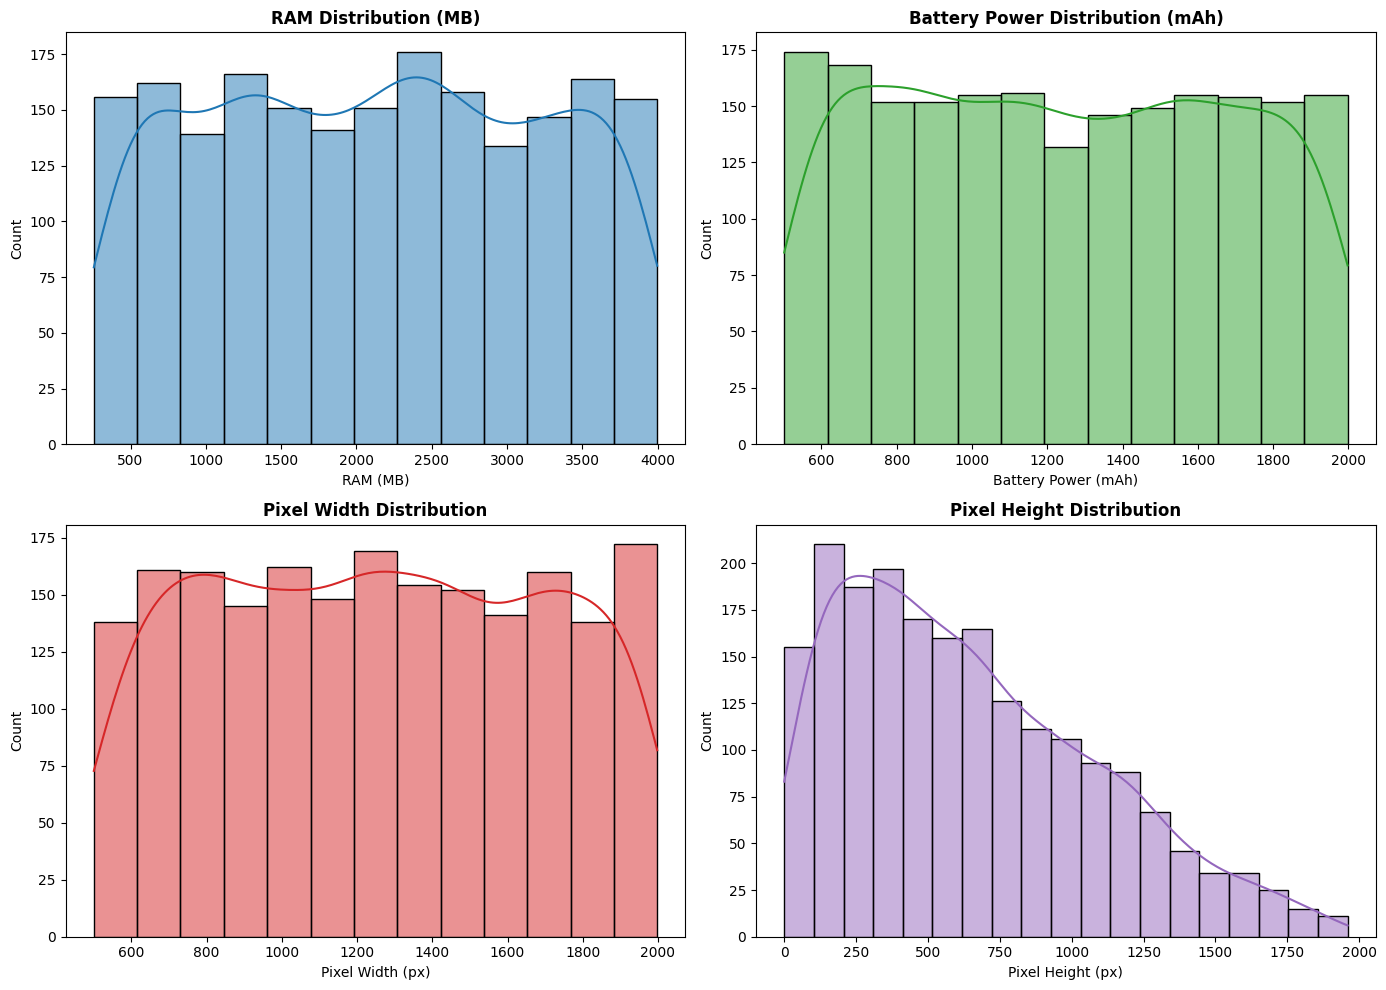

/tmp/ipykernel_1247/2632350977.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df, x='price_range', y='ram', palette='Blues')
/tmp/ipykernel_1247/2632350977.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Low (0)', 'Medium (1)', 'High (2)', 'Very High (3)'])
/tmp/ipykernel_1247/2632350977.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df, x='price_range', y='battery_power', palette='Greens')
/tmp/ipykernel_1247/2632350977.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or

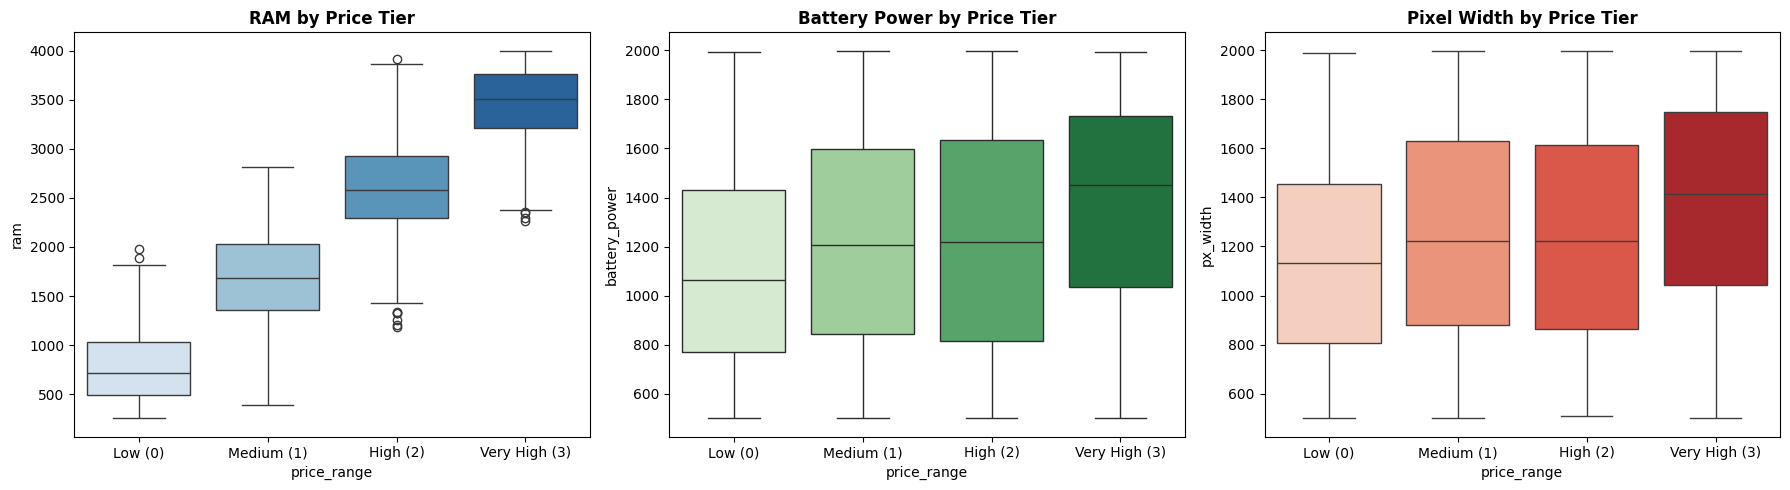

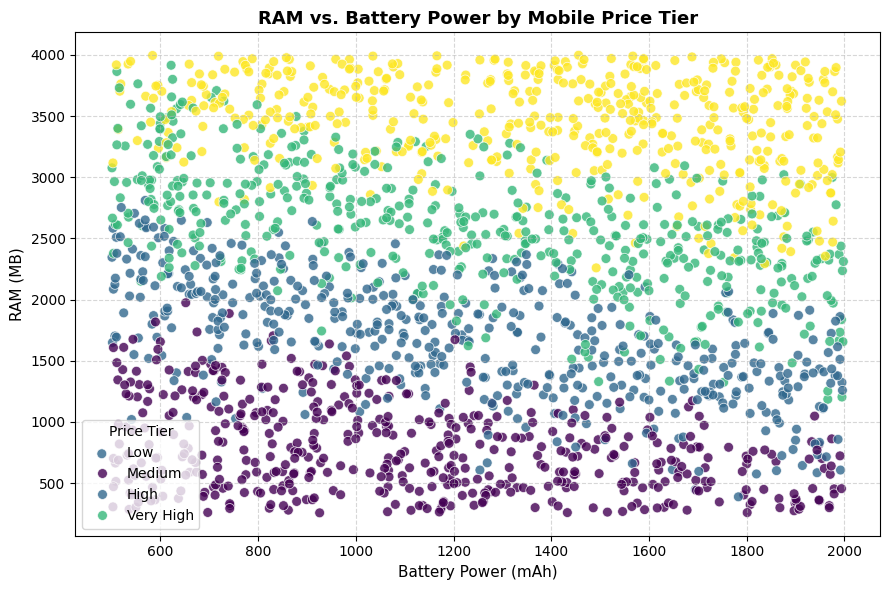

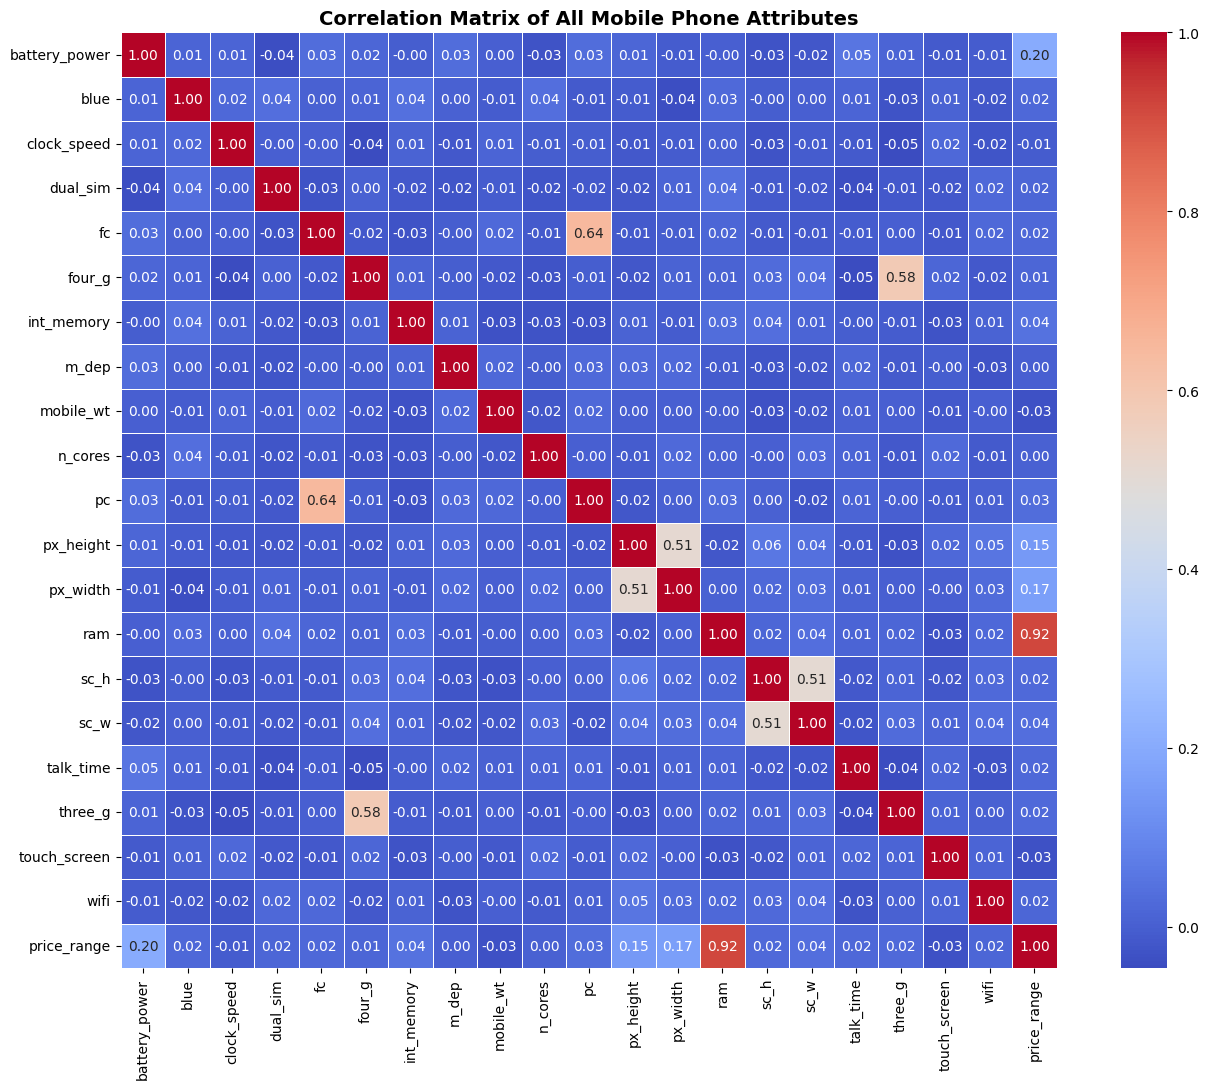

In [8]:
# 4. Data Visualization with Matplotlib & Seaborn

# A. Distribution Histograms & KDE for Key Continuous Features
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['ram'], kde=True, ax=axes[0, 0], color='#1f77b4')
axes[0, 0].set_title('RAM Distribution (MB)', fontweight='bold')
axes[0, 0].set_xlabel('RAM (MB)')

sns.histplot(df['battery_power'], kde=True, ax=axes[0, 1], color='#2ca02c')
axes[0, 1].set_title('Battery Power Distribution (mAh)', fontweight='bold')
axes[0, 1].set_xlabel('Battery Power (mAh)')

sns.histplot(df['px_width'], kde=True, ax=axes[1, 0], color='#d62728')
axes[1, 0].set_title('Pixel Width Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Pixel Width (px)')

sns.histplot(df['px_height'], kde=True, ax=axes[1, 1], color='#9467bd')
axes[1, 1].set_title('Pixel Height Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Pixel Height (px)')

plt.tight_layout()
plt.show()

# B. Box Plots: Feature Variations across Price Range Tiers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(ax=axes[0], data=df, x='price_range', y='ram', palette='Blues')
axes[0].set_title('RAM by Price Tier', fontweight='bold')
axes[0].set_xticklabels(['Low (0)', 'Medium (1)', 'High (2)', 'Very High (3)'])

sns.boxplot(ax=axes[1], data=df, x='price_range', y='battery_power', palette='Greens')
axes[1].set_title('Battery Power by Price Tier', fontweight='bold')
axes[1].set_xticklabels(['Low (0)', 'Medium (1)', 'High (2)', 'Very High (3)'])

sns.boxplot(ax=axes[2], data=df, x='price_range', y='px_width', palette='Reds')
axes[2].set_title('Pixel Width by Price Tier', fontweight='bold')
axes[2].set_xticklabels(['Low (0)', 'Medium (1)', 'High (2)', 'Very High (3)'])

plt.tight_layout()
plt.show()

# C. Scatter Plot with Decision Trend (RAM vs. Battery Power colored by Price Tier)
plt.figure(figsize=(9, 6))
scatter = sns.scatterplot(
    data=df,
    x='battery_power',
    y='ram',
    hue='price_range',
    palette='viridis',
    alpha=0.8,
    s=50
)
plt.title('RAM vs. Battery Power by Mobile Price Tier', fontsize=13, fontweight='bold')
plt.xlabel('Battery Power (mAh)', fontsize=11)
plt.ylabel('RAM (MB)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Price Tier', labels=['Low', 'Medium', 'High', 'Very High'])
plt.tight_layout()
plt.show()

# D. Comprehensive Correlation Heatmap
plt.figure(figsize=(14, 11))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True, linewidths=0.5)
plt.title('Correlation Matrix of All Mobile Phone Attributes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

>5. Insight Synthesis and Conclusion (Markdown Cell)

### Synthesis of Statistical Findings & Mobile Price Determinants

1. **Dominant Determinant — RAM (Random Access Memory):**
   * `ram` exhibits the strongest linear correlation with `price_range` ($r = 0.9170, p < 10^{-100}$).
   * The One-Way ANOVA across price tiers yields $F = 3520.11$ ($p = 0.0$), confirming that RAM separation is the primary structural divider separating price categories ($0 \to 3$).

2. **Secondary Physical Determinants:**
   * **Battery Power:** ($r = 0.2007, F = 31.60, p < 10^{-19}$) systematically scales higher in the premium tiers.
   * **Screen Resolution (`px_width` & `px_height`):** ($r \approx 0.15\text{--}0.17, p < 10^{-12}$) show statistically significant positive correlations with tier increases.

3. **Insignificant / Weak Attributes:**
   * Connectivity specs (`wifi`, `blue`, `dual_sim`, `four_g`, `three_g`) and aesthetic/physical dimensions (`m_dep`, `clock_speed`, `mobile_wt`) show near-zero correlation ($|r| < 0.05$) and non-significant Chi-Square test values ($p > 0.05$).
   * Camera megapixels (`fc`, `pc`) correlate with each other ($r = 0.64$) due to device generation pairing, but do not directly dictate price classification alone.

4. **Strategic Business Recommendation:**
   When positioning new mobile devices in target competitive brackets, allocating manufacturing spend to **RAM capacity** and **battery/display resolution** provides the most accurate and value-aligned product tiering.